# Model Training 2 - Random Forest Regressor
#### Using the [yggdrasil-decision-forest (ydf)](https://ydf.readthedocs.io/en/stable/py_api/RandomForestLearner/) library
## 1. Feature Selection / Data Tuning

In [34]:
# import libraries
import pandas as pd
from sklearn.model_selection import train_test_split
import ydf
import matplotlib.pyplot as plt
import plotly
from IPython.display import HTML
import seaborn as sns
%matplotlib inline

In [35]:
# read train and test data
train_df = pd.read_csv('../Data/Train.csv')
test_df = pd.read_csv('../Data/Test.csv')

In [37]:
# function to plot model evaluation
sns.set_theme(style="whitegrid")

def plot_model_evaluation(y_true, y_pred, title="Model Evaluation"):
    """
    Plot residual, prediction, and ground truth diagnostics for regression models.
    
    Parameters:
        y_true (array-like): Ground truth values
        y_pred (array-like): Model predictions
        title (str): Title of the overall plot
    """
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    residuals = y_pred - y_true

    # Create figure layout
    fig, axs = plt.subplots(3, 2, figsize=(14, 14))
    fig.suptitle(title, fontsize=16)

    # 1. Residual Histogram
    sns.histplot(residuals, bins=60, ax=axs[0, 0], color="C0")
    axs[0, 0].set_title("Residual Histogram")
    axs[0, 0].set_xlabel("Residual")
    axs[0, 0].set_ylabel("Density")

    # 2. Ground Truth Histogram
    sns.histplot(y_true, bins=60, ax=axs[0, 1], color="C0")
    axs[0, 1].set_title("Ground Truth Histogram")
    axs[0, 1].set_xlabel("Ground truth")
    axs[0, 1].set_ylabel("Density")

    # 3. Prediction Histogram
    sns.histplot(y_pred, bins=60, ax=axs[1, 0], color="C0")
    axs[1, 0].set_title("Prediction Histogram")
    axs[1, 0].set_xlabel("Prediction")
    axs[1, 0].set_ylabel("Density")

    # 4. Ground Truth vs Predictions (binned)
    df_gt_pred = pd.DataFrame({"ground_truth": y_true, "prediction": y_pred})
    df_gt_pred["gt_bin"] = pd.cut(df_gt_pred["ground_truth"], bins=30)
    binned_gt = df_gt_pred.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["prediction"], label="Prediction", color="darkorange")
    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["ground_truth"], linestyle="--", color="C0", label="Ideal")
    axs[1, 1].set_title("Ground Truth vs Predictions (Binned)")
    axs[1, 1].set_xlabel("Ground Truth")
    axs[1, 1].set_ylabel("Prediction")
    axs[1, 1].legend()

    # 5. Predictions vs Residual (binned)
    df_pred_res = pd.DataFrame({"prediction": y_pred, "residual": residuals})
    df_pred_res["pred_bin"] = pd.cut(df_pred_res["prediction"], bins=30)
    binned_pred = df_pred_res.groupby("pred_bin", observed=False).mean(numeric_only=True)

    axs[2, 0].plot(binned_pred["prediction"], binned_pred["residual"], color="darkorange")
    axs[2, 0].axhline(0, linestyle="--", color="C0")
    axs[2, 0].set_title("Predictions vs Residual (Binned)")
    axs[2, 0].set_xlabel("Prediction")
    axs[2, 0].set_ylabel("Residual")

    # 6. Ground Truth vs Residual (binned)
    df_gt_res = pd.DataFrame({"ground_truth": y_true, "residual": residuals})
    df_gt_res["gt_bin"] = pd.cut(df_gt_res["ground_truth"], bins=30)
    binned_gt_res = df_gt_res.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[2, 1].plot(binned_gt_res["ground_truth"], binned_gt_res["residual"], color="darkorange")
    axs[2, 1].axhline(0, linestyle="--", color="C0")
    axs[2, 1].set_title("Ground Truth vs Residual (Binned)")
    axs[2, 1].set_xlabel("Ground Truth")
    axs[2, 1].set_ylabel("Residual")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


### Model 1 - using all default features
Not use engineered feature 'DAYS_SINCE_LAUNCH' yet

In [41]:
# train model
features1 = ['OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 
             'EPOCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD']
model1 = ydf.RandomForestLearner(task=ydf.Task.REGRESSION, features=features1, label='LIFETIME').train(train_df, verbose=2)

Train model on 19579 examples
Model trained in 0:00:15.369420


In [42]:
description1 = model1.describe()
description1

In [43]:
# evaluate the model
evaluation1 = model1.evaluate(test_df)
print(evaluation1)

RMSE: 1451.29
num examples: 4895
num examples (weighted): 4895



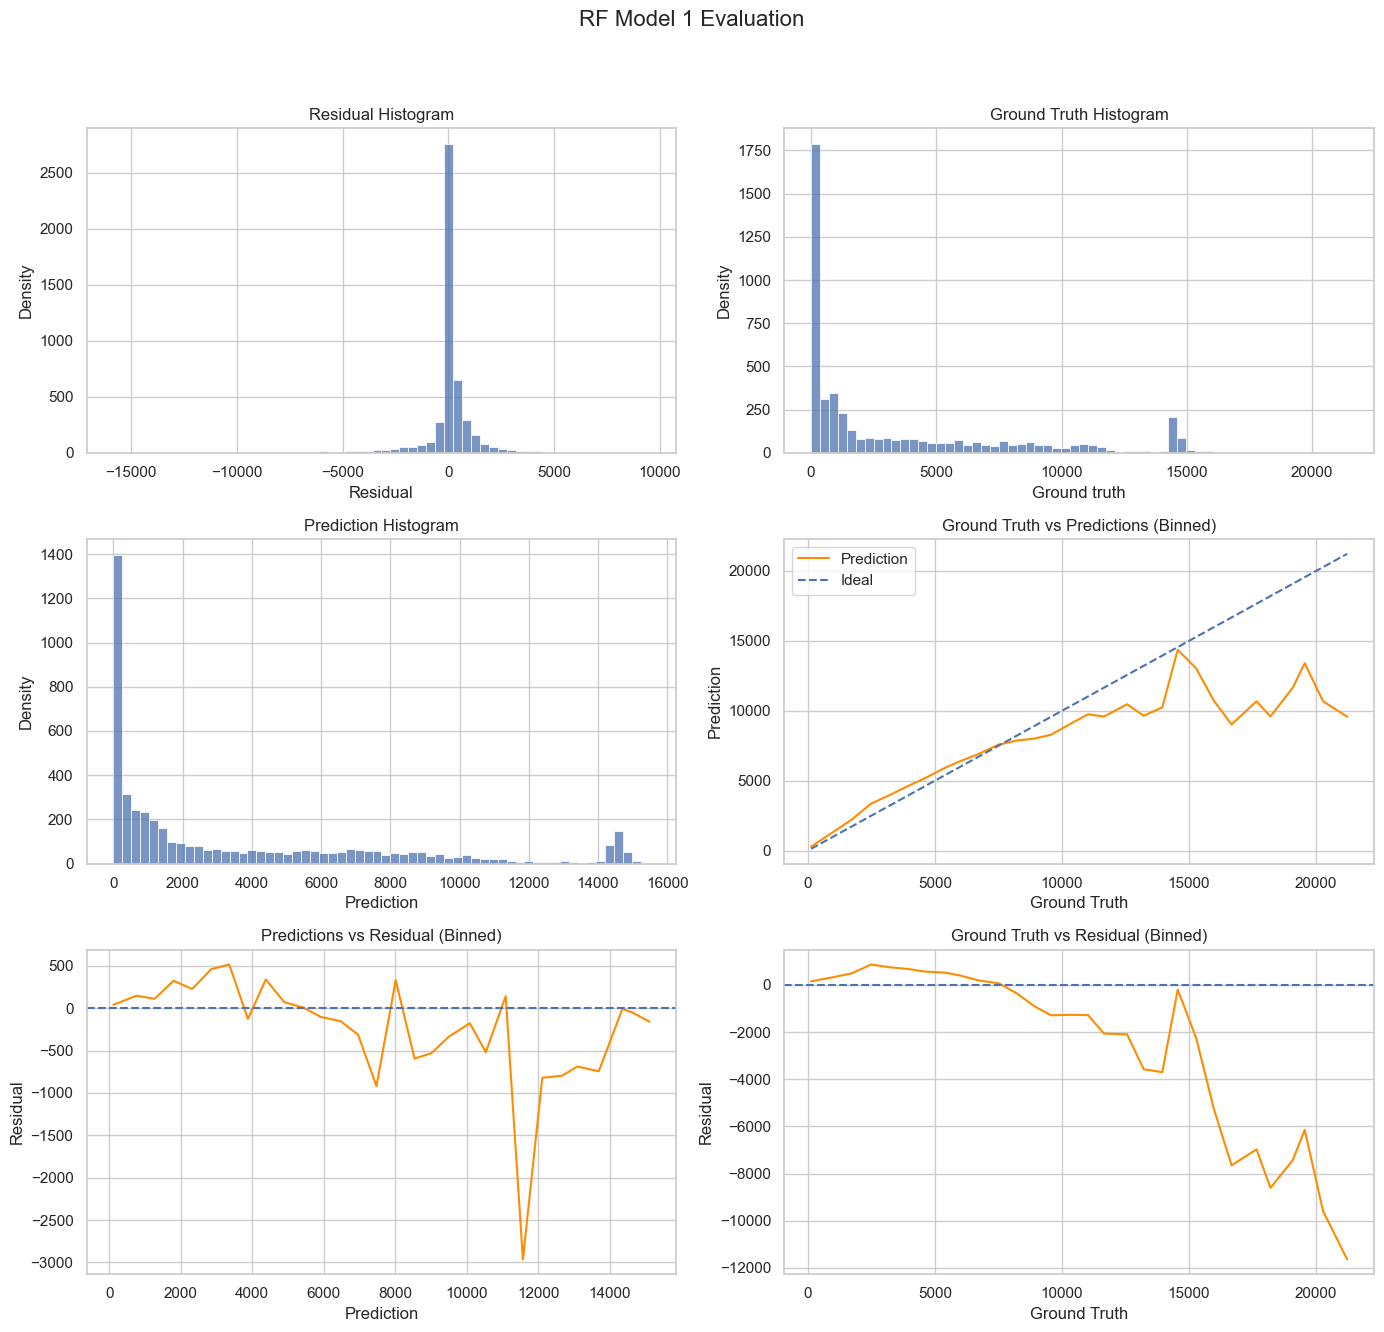

In [ ]:
# plot model evaluation
y_true = test_df['LIFETIME']
y_pred1 = model1.predict(test_df)
plot_model_evaluation(y_true, y_pred1, title="RF Model 1 Evaluation (default features)")

#### Interpretation
1. Residual Histogram: Many Predictions near 0 -> correct, right-side skew -> overestimating<br>
3. Prediction Histogram: Model underestimates the tail (compared to Ground Truth Histogram)<br>
4. Ground Truth vs. Predictions: Good accuracy for small lifetimes (tendency towards overestimating); Starting around 10k–12k, the line begins to flatten → the model underpredicts higher values (except good accuracy for objects with little below 15000 days lifetime, that appear more often in the data)
5. Prediction vs. Residual: near 0 residuals for low predictions -> good fit, as predictions increase the residuals increase sharply -> possibly missclassifies low-GT samples as high one

In [ ]:
# analyze the model
analysis1 = model1.analyze(test_df)
analysis1

#### Interpretation
Partial Dependence Plots:
- Rocket bodies decay faster on average than debris
- Country and Site have a significant (yet not physical) impact on lifetime as well, distribution very imbalanced (CIS/US and TTMTR/PKMTR most represented)
- Periapsis: the lower the periapsis the shorter the lifetime -> low orbits decay faster
- Mean Motion: higher mean motion -> lower orbit -> stronger drag -> shorter lifetime
- Revolution at Epoch: higher revs -> longer lifetime
- BSTAR: counterintuitive, higher drag should lead to objects decaying faster
- Semimajor Axis: the shorter the shorter the lifetime (measure for altitude)
- Mean Motion Dot: for most objects between 0 and 0.01
- Period: the longer the longer the lifetime

In [37]:
# save the model
model1.save('../Models/RF1.ydf')

### Model 2 - using all features 
Including engineered feature 'DAYS_SINCE_LAUNCH'

In [44]:
# train model
features2 = ['OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 
             'EPOCH', 'DAYS_SINCE_LAUNCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD']
model2 = ydf.RandomForestLearner(task=ydf.Task.REGRESSION, features=features2, label='LIFETIME').train(train_df, verbose=2)

Train model on 19579 examples
Model trained in 0:00:16.539566


In [45]:
description2 = model2.describe()
description2

In [46]:
# evaluate the model
evaluation2 = model2.evaluate(test_df)
print(evaluation2)

RMSE: 756.904
num examples: 4895
num examples (weighted): 4895



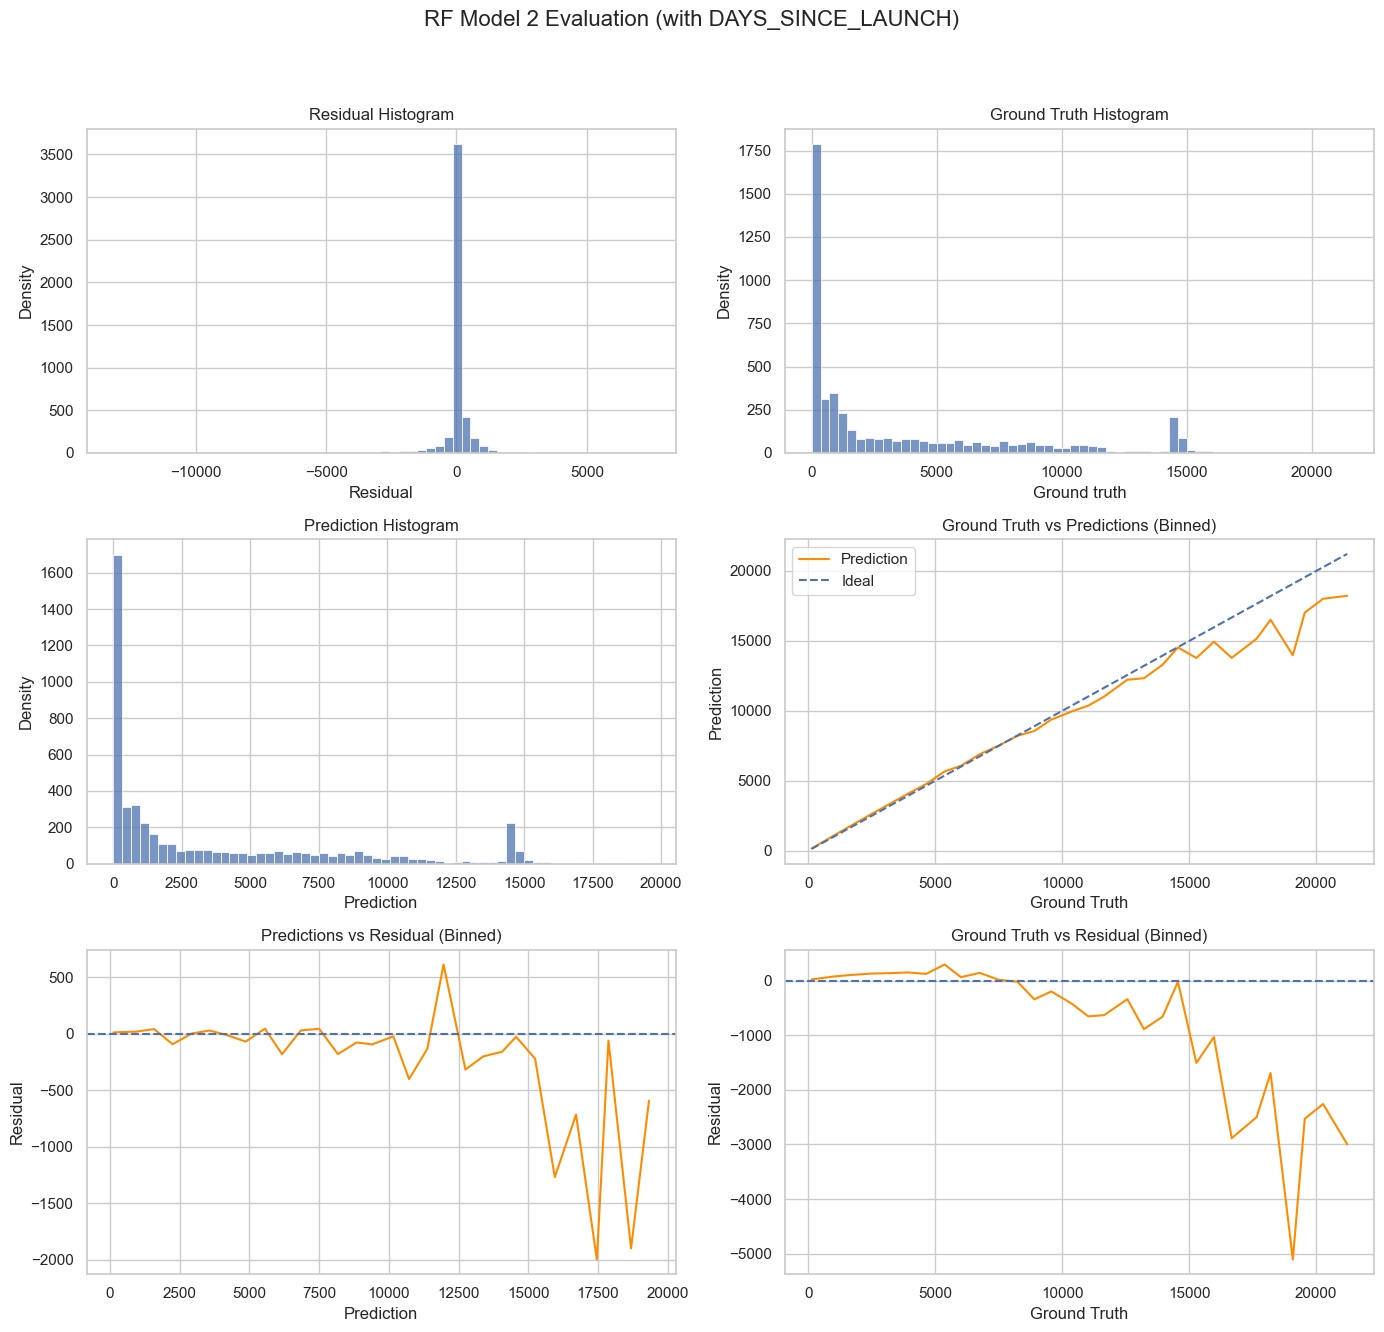

In [47]:
# plot model evaluation
y_pred2 = model2.predict(test_df)
plot_model_evaluation(y_true, y_pred2, title="RF Model 2 Evaluation (with DAYS_SINCE_LAUNCH)")

In [48]:
# analyze the model
analysis2 = model2.analyze(test_df)
analysis2

#### Interpretation
DAYS_SINCE_LAUNCH: Variable importance is not correct, difference from Model 1 (without) and Model 2 (with) is 1451.29 - 756.904 = 694.386

In [49]:
# save the model
model2.save('../Models/RF2.ydf')

### Model 3 - Remove not needed features 
(MEAN_ANOMALY, MEAN_MOTION_DDOT, ARG_OF_PERICENTER & EPOCH)

In [50]:
# train model
features3 = ['OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 
             'DAYS_SINCE_LAUNCH', 'PERIAPSIS', 'APOAPSIS', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'SEMIMAJOR_AXIS', 'PERIOD']
model3 = ydf.RandomForestLearner(task=ydf.Task.REGRESSION, features=features3, label='LIFETIME').train(train_df, verbose=2)

Train model on 19579 examples
Model trained in 0:00:17.583068


In [51]:
# describe model
description3 = model3.describe()
description3

In [52]:
# show rmse
evaluation3 = model3.evaluate(test_df)
print(evaluation3)

RMSE: 756.894
num examples: 4895
num examples (weighted): 4895



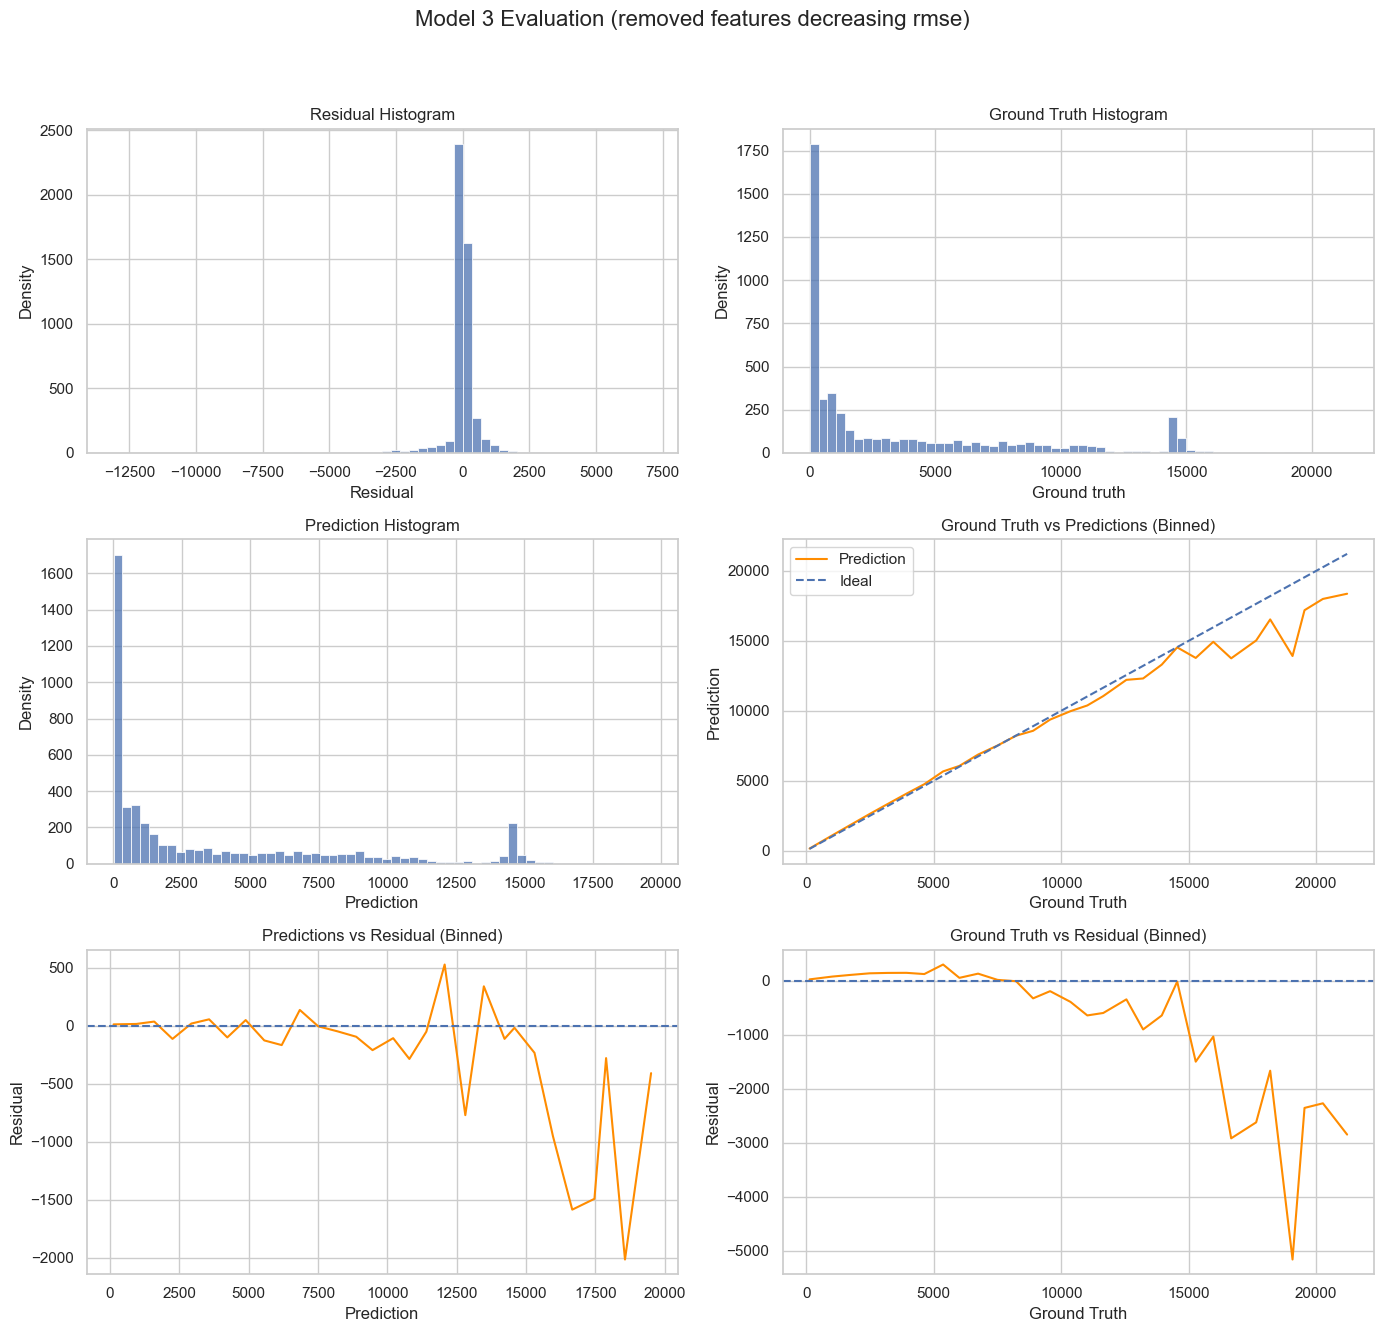

In [53]:
# evaluate modely_pred2 = model2.predict(test_df)
y_pred3 = model3.predict(test_df)
plot_model_evaluation(y_true, y_pred3, title="Model 3 Evaluation (removed features decreasing rmse)")

In [54]:
# analyze the model
analysis3 = model3.analyze(test_df)
analysis3

In [55]:
# save model
model3.save('../Models/RF3.ydf')